## Autorzy:
## Błażej Kazior 252758
## Hubert Gryl 250962


# Harmonogramowanie w zrobotyzowanej komórce: zadanie typu job-shop

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_4.ipynb)

W tym laboratorium planujemy pracę niewielkiej zautomatyzowanej komórki produkcyjnej. Przykład jest konkretny, a model odpowiada klasycznemu problemowi **harmonogramowania typu job-shop**.

Wybieramy czasy rozpoczęcia operacji tak, aby:

1. każdy zestaw przechodził przez wymaganą sekwencję stanowisk,
2. żadne stanowisko nie obsługiwało dwóch zestawów jednocześnie,
3. wszystkie zestawy były gotowe możliwie najwcześniej.

**Czas zakończenia wszystkich zadań** to *makespan*, zwykle oznaczany jako $C_{max}$.

## Pytania, które zbadamy

1. Jak zapisać opis komórki produkcyjnej jako zadania, stanowiska, operacje i czasy ich trwania?
2. Dlaczego potrzebujemy zmiennych binarnych, gdy dwie operacje konkurują o to samo stanowisko?
3. Jak zbudować niewielki mieszany model liniowy z całkowitoliczbowymi zmiennymi w PuLP?
4. Jak sprawdzić obliczony harmonogram przed zaufaniem wykresowi?
5. Jak odczytać produkcyjny wykres Gantta?

## Scenariusz: ostatnie minuty przed pokazem

Laboratorium robotyki przygotowuje cztery zestawy demonstracyjne przed przybyciem gości. Każdy zestaw musi odwiedzić trzy zautomatyzowane stanowiska, lecz kolejność zależy od zestawu.

Stanowiska mają w danych stałe angielskie nazwy:

- **Laser cutter** — wycinarka laserowa: wycina lub przycina części.
- **Robot arm** — ramię robota: montuje części.
- **Vision test** — kontrola wizyjna: sprawdza zestaw za pomocą kamery.

Nazwy zadań również pozostają kluczami danych: **Frame kit** to zestaw ramy, **Sensor mast** — maszt czujnika, **Gripper jaw** — szczęka chwytaka, a **Battery tray** — uchwyt akumulatora. Używaj tych samych kluczy przy odczycie tabel i zmianach danych.

Stanowisko może obsługiwać tylko jeden zestaw naraz. Zestaw może czekać między stanowiskami, ale nie może pominąć operacji ani zmienić własnej kolejności.

## Ilustracja komórki robotycznej

![Harmonogramowanie w zrobotyzowanej komórce](https://raw.githubusercontent.com/AdoHaha/automation_robotics_lab/refs/heads/master/job_illustration.png)

Ilustracja przedstawia współdzieloną komórkę: każdy zestaw ma ustaloną trasę, stanowiska obsługują po jednym zestawie, a oczekujące zestawy znajdują się w buforze.

In [ ]:
# PuLP 4.x nie działa z tym laboratorium, dlatego instalujemy wersję 3.3.0.
# Uruchom ten notatnik w nowej sesji Google Colab.
%pip install -q "PuLP==3.3.0"

import pulp
import pandas as pd
print("Wersja PuLP:", pulp.__version__)
if pulp.__version__ != "3.3.0":
    raise RuntimeError("Zrestartuj sesję Colab i uruchom wszystkie komórki ponownie.")

# Dane głównego ćwiczenia.
# Każde zadanie to trasa: (station, processing_time_in_minutes), czyli stanowisko i czas w minutach.
jobs = {
    "Frame kit": [
        ("Laser cutter", 3),
        ("Robot arm", 4),
        ("Vision test", 2),
    ],
    "Sensor mast": [
        ("Robot arm", 2),
        ("Laser cutter", 4),
        ("Vision test", 3),
    ],
    "Gripper jaw": [
        ("Laser cutter", 2),
        ("Vision test", 1),
        ("Robot arm", 3),
    ],
    "Battery tray": [
        ("Vision test", 2),
        ("Robot arm", 3),
        ("Laser cutter", 3),
    ],
}

# Zapisz krotki tras jako wiersze DataFrame, aby łatwo obejrzeć każdą operację.
operation_rows = []
for job, route in jobs.items():
    for operation, (station, duration) in enumerate(route, start=1):
        operation_rows.append({
            "job": job,
            "operation": operation,
            "station": station,
            "duration": duration,
        })

operations = pd.DataFrame(operation_rows)
operations

Wersja PuLP: 3.3.0


,job,operation,station,duration
0,Frame kit,1,Laser cutter,3
1,Frame kit,2,Robot arm,4
2,Frame kit,3,Vision test,2
3,Sensor mast,1,Robot arm,2
4,Sensor mast,2,Laser cutter,4
5,Sensor mast,3,Vision test,3
6,Gripper jaw,1,Laser cutter,2
7,Gripper jaw,2,Vision test,1
8,Gripper jaw,3,Robot arm,3
9,Battery tray,1,Vision test,2


## Odczytaj dane jako operacje

Każdy wiersz opisuje jedną operację. Na przykład **Frame kit** najpierw korzysta z wycinarki laserowej przez 3 minuty, następnie z ramienia robota przez 4 minuty, a na końcu z kontroli wizyjnej przez 2 minuty.

Tabela jest wejściem modelu harmonogramowania. Solver wybierze tylko czasy rozpoczęcia i kolejność operacji konkurujących o dane stanowisko. Nazwy kolumn pozostają zgodne z kodem: `job` — zadanie, `operation` — numer operacji, `station` — stanowisko, `duration` — czas trwania.

## Diagram tras

Tabela pozwala odczytać dokładne dane. Poniższy diagram przedstawia te same informacje jako ścieżki przez komórkę.

`plot_job_routes(jobs)` przyjmuje słownik tras i zwraca parę obiektów Matplotlib `(fig, ax)`. Rozmieszcza elementy według zadań i kolejności operacji, rysuje dla każdej krotki prostokąt w kolorze stanowiska i łączy kolejne operacje. Po zmianie tras użyj funkcji ponownie, aby sprawdzić zgodność sekwencji z opisem. Położenie prostokąta nie oznacza zoptymalizowanego czasu rozpoczęcia.

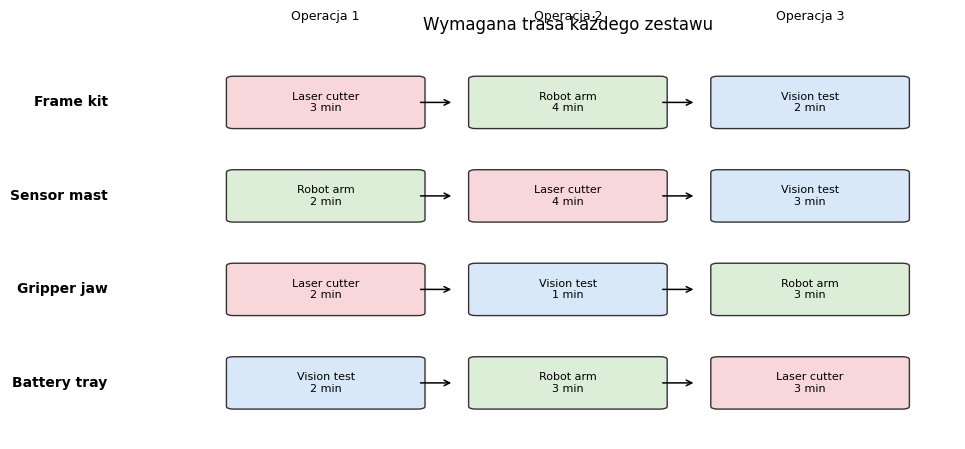

In [ ]:
# Pokaż kolejność operacji prostokątami w kolorach stanowisk; to nie jest harmonogram czasowy.
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch


def plot_job_routes(jobs):
    """Rysuje wymaganą trasę operacji każdego zadania, bez harmonogramowania.

    jobs przypisuje nazwom zadań uporządkowane krotki
    (station, processing_time_in_minutes). Pozycja x prostokąta oznacza
    kolejność operacji, nie czas rozpoczęcia; kolor oznacza stanowisko.
    Korzysta z globalnych plt i FancyBboxPatch. Tworzy figurę i zwraca
    (fig, ax) do wyświetlenia lub modyfikacji. Nie wymaga solvera."""
    station_colors = {
        "Laser cutter": "#F8D7DA",
        "Robot arm": "#DDEED8",
        "Vision test": "#D8E8F8",
    }

    # Współrzędne rozdzielają zadania pionowo, a etapy trasy poziomo.
    job_names = list(jobs)
    max_operations = max(len(route) for route in jobs.values())
    fig, ax = plt.subplots(figsize=(10, 0.9 * len(job_names) + 1.5))
    ax.set_xlim(0.4, max_operations + 0.6)
    ax.set_ylim(-0.6, len(job_names) - 0.4)
    ax.axis("off")

    # Narysuj prostokąty trasy i połącz je z kolejnymi wymaganymi operacjami.
    for y, job in enumerate(reversed(job_names)):
        ax.text(0.1, y, job, ha="right", va="center", fontsize=10, weight="bold")
        route = jobs[job]
        for operation, (station, duration) in enumerate(route, start=1):
            x = operation
            box = FancyBboxPatch(
                (x - 0.38, y - 0.25),
                0.76,
                0.5,
                boxstyle="round,pad=0.03",
                linewidth=1,
                edgecolor="#333333",
                facecolor=station_colors.get(station, "#EFEFEF"),
            )
            ax.add_patch(box)
            ax.text(x, y, f"{station}\n{duration} min", ha="center", va="center", fontsize=8)
            if operation < len(route):
                ax.annotate("", xy=(x + 0.53, y), xytext=(x + 0.38, y), arrowprops={"arrowstyle": "->", "lw": 1.1})

    for operation in range(1, max_operations + 1):
        ax.text(operation, len(job_names) - 0.15, f"Operacja {operation}", ha="center", va="bottom", fontsize=9)

    ax.set_title('Wymagana trasa każdego zestawu', pad=12)
    return fig, ax


plot_job_routes(jobs);

## Rozgrzewka: dwa zadania i dwa stanowiska

Najpierw rozwiąż ręcznie mały przykład.

- Zadanie A (`Job A`): `Station 1` przez 5 minut, następnie `Station 2` przez 6 minut.
- Zadanie B (`Job B`): `Station 2` przez 4 minuty, następnie `Station 1` przez 7 minut.

`Station 1` i `Station 2` oznaczają stanowiska 1 i 2; angielskie nazwy są kluczami danych.

Pytania:

1. Czy obie pierwsze operacje mogą rozpocząć się w chwili 0?
2. Co musi się wydarzyć, zanim zadanie A skorzysta ze stanowiska 2?
3. Co musi się wydarzyć, zanim zadanie B skorzysta ze stanowiska 1?
4. Narysuj ręcznie harmonogram. Optymalny czas zakończenia wszystkich zadań wynosi **12 minut**.

Na każdym stanowisku albo A poprzedza B, albo B poprzedza A. Tę decyzję „albo–albo” reprezentuje zmienna binarna.

In [ ]:
# Zapisz przykład dwóch zadań i przekształć go w czytelną tabelę operacji.
warmup_jobs = {
    "Job A": [
        ("Station 1", 5),
        ("Station 2", 6),
    ],
    "Job B": [
        ("Station 2", 4),
        ("Station 1", 7),
    ],
}

warmup_rows = []
for job, route in warmup_jobs.items():
    for operation, (station, duration) in enumerate(route, start=1):
        warmup_rows.append({
            "job": job,
            "operation": operation,
            "station": station,
            "duration": duration,
        })

pd.DataFrame(warmup_rows)


,job,operation,station,duration
0,Job A,1,Station 1,5
1,Job A,2,Station 2,6
2,Job B,1,Station 2,4
3,Job B,2,Station 1,7


## Idea modelu

Dla każdej operacji tworzymy zmienną czasu rozpoczęcia:

$$s_{j,k} \ge 0$$

gdzie $j$ oznacza zadanie, a $k$ — numer operacji w tym zadaniu.

Model zawiera trzy grupy ograniczeń.

### 1. Kolejność operacji w zadaniu

Jeśli operacja 2 następuje po operacji 1, nie może rozpocząć się przed zakończeniem operacji 1:

$$s_{j,2} \ge s_{j,1} + p_{j,1}$$

### 2. Brak nakładania się operacji na jednym stanowisku

Jeśli operacje `a` i `b` wymagają tego samego stanowiska, jedna musi poprzedzać drugą. Wprowadzamy zmienną binarną $y_{a,b}$.

Dla $y_{a,b}=1$ operacja `a` poprzedza `b`; dla $y_{a,b}=0$ operacja `b` poprzedza `a`.

Dwa ograniczenia typu duże M (Big-M) mają postać:

$$s_b \ge s_a + p_a - M(1-y_{a,b})$$

$$s_a \ge s_b + p_b - My_{a,b}$$

Składnik z dużym M działa jak przełącznik. Po wybraniu kolejności jedno ograniczenie jest aktywne i zapobiega nakładaniu się operacji. Drugie zawiera duże odejmowanie, więc przestaje ograniczać harmonogram. $M$ musi być dostatecznie duże, aby wyłączyć nieaktywny warunek, lecz nie przesadnie duże. Tutaj przyjmujemy sumę czasów wszystkich operacji: to bezpieczny horyzont tego podstawowego modelu, ponieważ nawet wykonywanie operacji pojedynczo zakończyłoby się do tej chwili. Jeśli dodasz czasy dostępności zadań, okna konserwacji lub inne warunki wymuszające przestoje, zwiększ horyzont, aby duże M nadal było wystarczające.

### 3. Czas zakończenia wszystkich zadań

Czas zakończenia wszystkich zadań musi być nie mniejszy od czasu zakończenia ostatniej operacji każdego zadania:

$$C_{max} \ge s_{j,last} + p_{j,last}$$

Funkcja celu:

$$\min C_{max}$$

### Solver wielokrotnego użytku: słownik tras → tabela harmonogramu

`solve_jobshop(jobs, msg=False, horizon=None)` przyjmuje uporządkowany słownik tras, tworzy zmienne czasu i kolejności, dodaje ograniczenia tras, rozłączności oraz czasu zakończenia, rozwiązuje model i zapisuje optymalne czasy w DataFrame. Zwraca `(makespan, schedule, model)`, więc rozgrzewka i główny przykład korzystają z tej samej implementacji. Klucze `(job, operation_index)` identyfikują operacje: wewnętrzne indeksy zaczynają się od zera, a numery w tabeli — od jednego. Pomocnicze funkcje `_safe_name` i `_operation_name` tworzą czytelne nazwy solvera z etykiet i krotek. Gdy solver nie znajdzie optimum, funkcja zgłasza błąd przed odczytaniem harmonogramu.

In [ ]:
from itertools import combinations
import re
import pulp
import pandas as pd

def _safe_name(text):
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(text)).strip("_")

def _operation_name(operation):
    job, index = operation
    return f"{_safe_name(job)}_op{index + 1}"

def solve_jobshop(jobs, msg=False, horizon=None, maintenance=None, due_dates=None, tardiness_weight=0.5):
    model = pulp.LpProblem("Robot_Cell_Job_Shop", pulp.LpMinimize)

    operations = [
        (job, operation_index)
        for job, route in jobs.items()
        for operation_index in range(len(route))
    ]
    station_of = {
        (job, operation_index): jobs[job][operation_index][0]
        for job, operation_index in operations
    }
    duration = {
        (job, operation_index): jobs[job][operation_index][1]
        for job, operation_index in operations
    }
    if horizon is None:
        horizon = sum(duration[operation] for operation in operations)

    # Tworzenie zmiennych zgodne z PuLP 3.3.0
    start = {}
    for operation in operations:
        var = pulp.LpVariable(f"start__{_operation_name(operation)}", lowBound=0)
        start[operation] = var

    cmax = pulp.LpVariable("Cmax", lowBound=0)

    model += cmax, "minimize_makespan"

    # Ograniczenia trasy: operacje zadania zachowują wymaganą kolejność.
    for job, route in jobs.items():
        for operation_index in range(len(route) - 1):
            current_operation = (job, operation_index)
            next_operation = (job, operation_index + 1)
            model += (
                start[next_operation] >= start[current_operation] + duration[current_operation],
                f"route__{_operation_name(current_operation)}__before__{_operation_name(next_operation)}",
            )

    # Ograniczenia rozłączności: operacje jednego stanowiska nie mogą nakładać się w czasie.
    stations = sorted({station for route in jobs.values() for station, _ in route})
    for station in stations:
        station_operations = [operation for operation in operations if station_of[operation] == station]
        for first_operation, second_operation in combinations(station_operations, 2):
            order = pulp.LpVariable(f"order__{_safe_name(station)}__{_operation_name(first_operation)}__before__{_operation_name(second_operation)}", cat=pulp.LpBinary)
            model += (
                start[second_operation]
                >= start[first_operation] + duration[first_operation] - horizon * (1 - order),
                f"no_overlap__{_safe_name(station)}__{_operation_name(first_operation)}__before__{_operation_name(second_operation)}",
            )
            model += (
                start[first_operation]
                >= start[second_operation] + duration[second_operation] - horizon * order,
                f"no_overlap__{_safe_name(station)}__{_operation_name(second_operation)}__before__{_operation_name(first_operation)}",
            )

    # Cmax musi przypadać po zakończeniu ostatniej operacji każdego zadania.
    for job, route in jobs.items():
        last_operation = (job, len(route) - 1)
        model += (
            cmax >= start[last_operation] + duration[last_operation],
            f"makespan_after__{_safe_name(job)}",
        )

    # Okno konserwacji: operacja kończy się przed przerwą albo zaczyna po niej.
    if maintenance:
        for station, (break_start, break_end) in maintenance.items():
            for operation in operations:
                if station_of[operation] == station:
                    before = pulp.LpVariable(f"maintenance__{_operation_name(operation)}", cat=pulp.LpBinary)
                    model += start[operation] + duration[operation] <= break_start + horizon * (1 - before)
                    model += start[operation] >= break_end - horizon * before

    # Opcjonalna kara za spóźnienie.
    if due_dates:
        late = []
        for job, due_day in due_dates.items():
            last_operation = (job, len(jobs[job]) - 1)
            tardiness = pulp.LpVariable(f"late__{_safe_name(job)}", lowBound=0)
            model += tardiness >= start[last_operation] + duration[last_operation] - due_day
            late.append(tardiness)
        model.setObjective(cmax + tardiness_weight * pulp.lpSum(late))

    # Rozwiąż model
    solver = pulp.PULP_CBC_CMD(msg=msg)
    model.solve(solver)

    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        raise RuntimeError(f"Status solvera: {status}; oczekiwano Optimal.")

    # Zapisz optymalne początki
    rows = []
    for job, route in jobs.items():
        for operation_index, (station, processing_time) in enumerate(route):
            operation = (job, operation_index)
            start_time = pulp.value(start[operation])
            if start_time is None:
                raise RuntimeError(f"Brak czasu rozpoczęcia dla {job}, op. {operation_index + 1}.")
            rows.append({
                "job": job,
                "operation": operation_index + 1,
                "station": station,
                "start": start_time,
                "duration": processing_time,
                "finish": start_time + processing_time,
            })

    schedule = (
        pd.DataFrame(rows)
        .sort_values(["station", "start", "job"])
        .reset_index(drop=True)
    )
    return pulp.value(cmax), schedule, model

In [ ]:
# Najpierw użyj solvera dla przykładu sprawdzonego ręcznie, potem dla pełnej komórki.
warmup_makespan, warmup_schedule, warmup_model = solve_jobshop(warmup_jobs)
print(f"Optymalny czas zakończenia wszystkich zadań rozgrzewki: {warmup_makespan:.0f} minut")
print('Oczekiwana wartość dla pierwotnych danych rozgrzewki: 12 minut')
warmup_schedule


Optymalny czas zakończenia wszystkich zadań rozgrzewki: 12 minut
Oczekiwana wartość dla pierwotnych danych rozgrzewki: 12 minut


,job,operation,station,start,duration,finish
0,Job A,1,Station 1,0.0,5,5.0
1,Job B,2,Station 1,5.0,7,12.0
2,Job B,1,Station 2,0.0,4,4.0
3,Job A,2,Station 2,5.0,6,11.0


In [ ]:
# Rozwiąż główny przykład tą samą funkcją i obejrzyj harmonogram w minutach.
makespan, schedule, model = solve_jobshop(jobs)
print(f"Optymalny czas zakończenia wszystkich zadań komórki: {makespan:.0f} minut")
print('Oczekiwana wartość dla pierwotnych danych komórki: 13 minut')
schedule


Optymalny czas zakończenia wszystkich zadań komórki: 13 minut
Oczekiwana wartość dla pierwotnych danych komórki: 13 minut


,job,operation,station,start,duration,finish
0,Frame kit,1,Laser cutter,0.0,3,3.0
1,Sensor mast,2,Laser cutter,3.0,4,7.0
2,Gripper jaw,1,Laser cutter,7.0,2,9.0
3,Battery tray,3,Laser cutter,10.0,3,13.0
4,Sensor mast,1,Robot arm,0.0,2,2.0
5,Frame kit,2,Robot arm,3.0,4,7.0
6,Battery tray,2,Robot arm,7.0,3,10.0
7,Gripper jaw,3,Robot arm,10.0,3,13.0
8,Battery tray,1,Vision test,0.0,2,2.0
9,Frame kit,3,Vision test,7.0,2,9.0


## Sprawdź harmonogram przed narysowaniem wykresu

Wykres Gantta ułatwia oglądanie harmonogramu, ale najpierw automatycznie sprawdź reguły.

Poprawny harmonogram spełnia dwa warunki:

1. każde zadanie zachowuje kolejność swojej trasy,
2. operacje na tym samym stanowisku nie nakładają się w czasie.

`validate_schedule(jobs, schedule, tolerance=1e-7)` przyjmuje pierwotne trasy i tabelę harmonogramu. Indeksuje wiersze krotkami operacji, sprawdza kolejność, a następnie grupuje i sortuje operacje według stanowisk, aby porównać sąsiednie przedziały. Zwraca komunikat potwierdzający poprawność albo zgłasza błąd asercji przy naruszeniu reguły. Uruchamiaj ją po każdym rozwiązaniu scenariusza; tolerancja to niewielka liczba minut uwzględniająca błędy numeryczne solvera.

In [ ]:
# Sprawdź reguły harmonogramu niezależnie od modelu optymalizacji.
def validate_schedule(jobs, schedule, tolerance=1e-7):
    """Sprawdza kolejność tras i rozłączność operacji w rozwiązanym harmonogramie.

    jobs to uporządkowany słownik tras użyty w modelu. schedule jest tabelą
    z solve_jobshop, z numerami operacji od 1 i start/finish w minutach.
    tolerance=1e-7 minut pomija szum numeryczny. Zakłada obecność wszystkich
    operacji modelu w tabeli. Zwraca "Harmonogram jest poprawny.", jeśli
    oba warunki są spełnione; w przeciwnym razie zgłasza AssertionError.
    Nie uruchamia solvera ani niczego nie wyświetla. Wywołuj po każdym
    ponownym rozwiązaniu, przed rysowaniem wykresu."""
    # Indeksuj wiersze krotkami, aby łatwo porównać kolejne operacje trasy.
    indexed = {
        (row.job, int(row.operation) - 1): row
        for row in schedule.itertuples(index=False)
    }

    # Następnik nie może rozpocząć się przed zakończeniem poprzednika.
    for job, route in jobs.items():
        for operation_index in range(len(route) - 1):
            current_operation = indexed[(job, operation_index)]
            next_operation = indexed[(job, operation_index + 1)]
            if next_operation.start + tolerance < current_operation.finish:
                raise AssertionError(
                    f"Naruszenie trasy zadania {job}: operacja {operation_index + 2} "
                    f"zaczyna się przed zakończeniem operacji {operation_index + 1}."
                )

    # Posortuj operacje stanowiska w czasie i sprawdź nakładanie sąsiednich przedziałów.
    for station, station_schedule in schedule.groupby("station"):
        ordered = station_schedule.sort_values("start")
        previous_operation = None
        for operation in ordered.itertuples(index=False):
            if (
                previous_operation is not None
                and operation.start + tolerance < previous_operation.finish
            ):
                raise AssertionError(
                    f"Nakładanie operacji na {station}: {previous_operation.job} i {operation.job}."
                )
            previous_operation = operation

    return 'Harmonogram jest poprawny.'


validate_schedule(warmup_jobs, warmup_schedule), validate_schedule(jobs, schedule)

('Harmonogram jest poprawny.', 'Harmonogram jest poprawny.')

## Funkcja wykresu Gantta: tabela → oś czasu stanowisk

`plot_gantt(schedule, title=...)` przyjmuje sprawdzoną tabelę harmonogramu i zwraca `(fig, ax)`. Przypisuje stanowiskom wiersze, a zadaniom kolory; rysuje operacje od ich czasów rozpoczęcia, z szerokością równą czasowi trwania, a następnie dodaje etykiety minut, stanowisk i legendę zadań. Po zmianie tras lub czasów użyj jej ponownie. Funkcja pokazuje podane wartości — nie rozwiązuje modelu ani nie sprawdza harmonogramu.

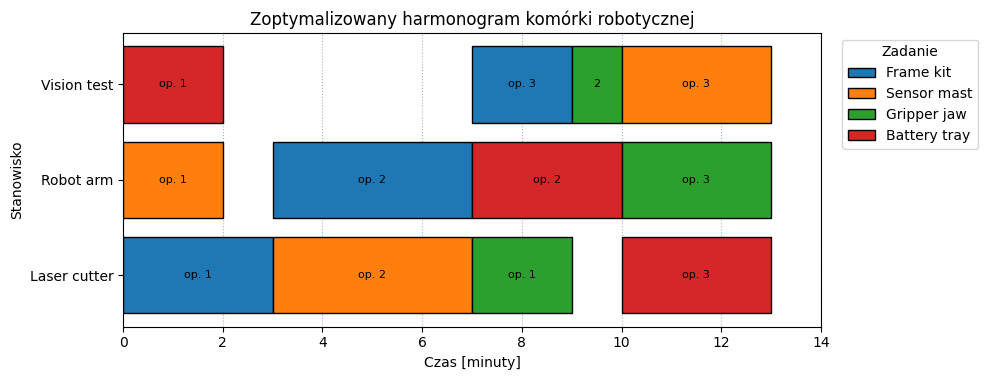

In [ ]:
# Narysuj sprawdzony harmonogram jako paski na osiach czasu stanowisk.
import matplotlib.pyplot as plt


def plot_gantt(schedule, title='Zoptymalizowany harmonogram komórki robotycznej'):
    """Tworzy wykres Gantta stanowisko–czas z tabeli rozwiązanego harmonogramu.

    schedule ma kolumny job, operation, station, start, duration, finish;
    wszystkie czasy są w minutach. title domyślnie opisuje zoptymalizowany
    harmonogram komórki. Korzysta z globalnego plt; kolor identyfikuje
    zadanie, a wiersz — stanowisko. Zwraca (fig, ax) do wyświetlenia lub
    modyfikacji. Rysuje podane dane bez rozwiązywania modelu i sprawdzania
    reguł; najpierw wywołaj validate_schedule."""
    # Przypisz stanowiskom pozycje y, a zadaniom spójne kolory.
    stations = list(schedule["station"].drop_duplicates())
    jobs_in_schedule = list(schedule["job"].drop_duplicates())
    y_position = {station: index for index, station in enumerate(stations)}
    color_map = {
        job: plt.get_cmap("tab10")(index % 10)
        for index, job in enumerate(jobs_in_schedule)
    }

    fig_height = max(3.5, 0.8 * len(stations) + 1.5)
    fig, ax = plt.subplots(figsize=(10, fig_height))
    labelled_jobs = set()

    # Wiersze tabeli wyznaczają początek i szerokość pasków oraz jedną etykietę legendy na zadanie.
    for row in schedule.itertuples(index=False):
        y = y_position[row.station]
        label = row.job if row.job not in labelled_jobs else None
        labelled_jobs.add(row.job)

        ax.barh(
            y,
            row.duration,
            left=row.start,
            color=color_map[row.job],
            edgecolor="black",
            label=label,
        )
        operation_label = f"op. {int(row.operation)}" if row.duration >= 1.8 else str(int(row.operation))
        ax.text(
            row.start + row.duration / 2,
            y,
            operation_label,
            ha="center",
            va="center",
            fontsize=8,
        )

    # Podpisz minuty i stanowiska oraz pozostaw miejsce na legendę zadań.
    ax.set_yticks(list(y_position.values()))
    ax.set_yticklabels(list(y_position.keys()))
    ax.set_xlabel('Czas [minuty]')
    ax.set_ylabel('Stanowisko')
    ax.set_title(title)
    ax.set_xlim(0, schedule["finish"].max() + 1)
    ax.grid(axis="x", linestyle=":")
    ax.set_axisbelow(True)
    ax.legend(title='Zadanie', bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    return fig, ax


plot_gantt(schedule);

## Zadania do wykonania

### Zadanie 1 — wskaż elementy optymalizacji

✅


**Odpowiedź**

- Zadania: Frame kit, Sensor mast, Gripper jaw, Battery tray.
- Stanowiska: Laser cutter, Robot arm, Vision test.
- Zmienne decyzyjne: czasy rozpoczęcia operacji, czas końca wszystkich zadań i zmienne binarne określające kolejność.
- Funkcja celu: jak najkrótszy czas zakończenia wszystkich zadań.
- Ograniczenia: trzeba zachować kolejność operacji, a stanowisko może pracować tylko nad jednym zadaniem naraz.

### Zadanie 2 — szybszy chwytak robota

Każda operacja Robot arm trwa o minutę krócej, ale minimum minutę.

In [ ]:
new_jobs = {}
for job, route in jobs.items():
    new_jobs[job] = []
    for station, duration in route:
        if station == "Robot arm":
            duration = max(1, duration - 1)
        new_jobs[job].append((station, duration))

new_time, new_schedule, _ = solve_jobshop(new_jobs)
print("Nowy czas:", new_time)
print("Poprawa:", makespan - new_time)
print(validate_schedule(new_jobs, new_schedule))

Nowy czas: 12.0
Poprawa: 1.0
Harmonogram jest poprawny.


✅

**Odpowiedź do zadania 2:** Czas skraca się z 13 do 12 minut, czyli o 1 minutę.

### Zadanie 3 — wąskie gardła

✅


**Odpowiedź**

1. Laser cutter pracuje łącznie 12 minut. Robot arm też pracuje 12 minut.
2. Vision test ma najwięcej bezczynności, bo pracuje tylko 8 minut.
3. Sensor mast kończy się w 13. minucie. Również Gripper jaw i Battery tray mogą zakończyć się w tej chwili.
4. Nie. Wąskie gardło to zajęte stanowisko, które ogranicza pracę całej komórki, a niekoniecznie ostatni zestaw.

### Zadanie 4 — konserwacja Vision test od 4. do 6. minuty

✅


**Odpowiedź:** Każda operacja Vision test musi zakończyć się przed minutą 4 albo zacząć po minucie 6. W kodzie funkcji dodano taki warunek przez zmienną binarną.

Czas po uwzględnieniu konserwacji: 13.0
Harmonogram jest poprawny.


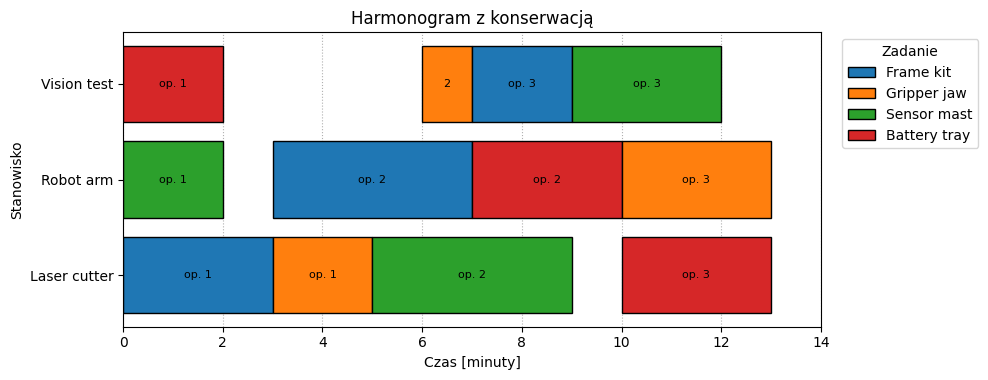

In [ ]:
maintenance_time, maintenance_schedule, _ = solve_jobshop(
    jobs, maintenance={"Vision test": (4, 6)}
)
print("Czas po uwzględnieniu konserwacji:", maintenance_time)
print(validate_schedule(jobs, maintenance_schedule))
plot_gantt(maintenance_schedule, title="Harmonogram z konserwacją");

### Wyzwanie — termin Frame kit

Frame kit ma być gotowy do 10. minuty. Spóźnienie to czas po terminie, ale nie mniej niż zero.

✅

**Odpowiedź:** Można jednocześnie zmniejszać czas zakończenia wszystkich zadań oraz dodawać niewielką karę za spóźnienie Frame kit. W tym przykładzie używam wzoru `makespan + 0.5 * spóźnienie`.

In [ ]:
late_time, late_schedule, _ = solve_jobshop(
    jobs, due_dates={"Frame kit": 10}, tardiness_weight=0.5
)
frame_finish = late_schedule[late_schedule["job"] == "Frame kit"]["finish"].max()
print("Czas wszystkich zadań:", late_time)
print("Spóźnienie Frame kit:", max(0, frame_finish - 10))

Czas wszystkich zadań: 13.0
Spóźnienie Frame kit: 0


✅
# Wnioski

### Rozgrzewka — dwa zadania
- Obie pierwsze operacje mogą zacząć się w chwili 0, ponieważ korzystają z różnych stanowisk (A ze Station 1, B ze Station 2).
- A może wejść na Station 2 dopiero wtedy, gdy skończy swoją operację na Station 1 i gdy Station 2 będzie wolne.
- B może wejść na Station 1 dopiero wtedy, gdy skończy swoją operację na Station 2 i gdy zwolni się Station 1.
- Solver potwierdził ręczny wynik 12 minut: A pracuje na Station 1 w minutach 0–5, a B wchodzi tam od razu po nim (5–12).

### Zadanie 1 — elementy modelu
- Zadania: Frame kit, Sensor mast, Gripper jaw, Battery tray. Stanowiska: Laser cutter, Robot arm, Vision test.
-Zmienne: czasy rozpoczęcia 12 operacji, $Cmax$ oraz zmienne binarne kolejności. Zmienna binarna jest potrzebna, bo na każdym stanowisku mamy decyzję „albo A przed B, albo B przed A”, której nie da się zapisać zwykłą liniową nierównością.
- Cel: minimalny czas zakończenia wszystkich zadań $Cmax$.
-Ograniczenia: kolejność operacji w zadaniu, brak nakładania się operacji na stanowisku (Big-M), $Cmax$ ≥ koniec każdego zadania.

### Wynik bazowy: 13 minut
- Suma wszystkich operacji to 32 min, a harmonogram trwa tylko 13 min, ponieważ stanowiska pracują równolegle.
- Dolna granica: Laser cutter i Robot arm mają po 12 min pracy, więc żaden harmonogram nie może być krótszy niż 12 min. Solver znalazł 13 min. Brakującej minuty nie da się „zmieścić”, bo kolejność tras wymusza minutę przestoju na obu stanowiskach.
- Przed narysowaniem wykresu harmonogram sprawdziliśmy funkcją validate_schedule. Kolejność tras jest zachowana i nic się nie nakłada.

### Zadanie 3 — wąskie gardła

| Stanowisko | Praca | Bezczynność (do 13 min) | Wykorzystanie |
|---|---|---|---|
| Laser cutter | 12 min | 1 min | 92% |
| Robot arm | 12 min | 1 min | 92% |
| Vision test | 8 min | 5 min | 62% |

-Najbardziej obciążone są Laser cutter i Robot arm. Najwięcej przestoju ma Vision test.
- W 13. minucie kończą się aż trzy zadania: Sensor mast, Gripper jaw i Battery tray. Frame kit kończy się już w 9. minucie.
- Ostatnie zadanie to nie to samo co wąskie gardło. Wąskie gardło to stanowisko, które ogranicza całą komórkę, a ostatni zestaw może po prostu czekać na zajęte stanowisko.

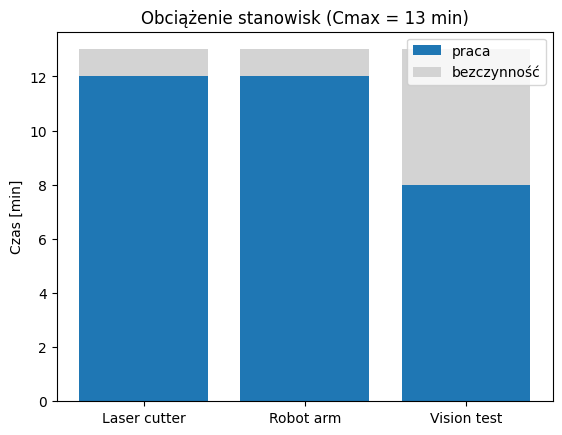

In [ ]:
praca = schedule.groupby("station")["duration"].sum()
przestoj = makespan - praca

plt.bar(praca.index, praca, label="praca")
plt.bar(praca.index, przestoj, bottom=praca, color="lightgray", label="bezczynność")
plt.ylabel("Czas [min]")
plt.title(f"Obciążenie stanowisk (Cmax = {makespan:.0f} min)")
plt.legend()
plt.show()

Rys. 1. Obciążenie stanowisk w harmonogramie bazowym. Laser cutter i Robot arm pracują 12 z 13 minut, a Vision test stoi wolny przez 5 minut.

### Zadanie 2 — szybszy chwytak robota
- Skrócenie każdej operacji Robot arm o 1 min skraca harmonogram z 13 do 12 min, czyli o 1 min, mimo że robot oszczędza łącznie 4 min pracy.
- Dalej poprawić się nie da, ponieważ Laser cutter nadal ma 12 min pracy. Teraz to on wyznacza dolną granicę i pracuje bez przerwy (Rys. 2).
- Nie każda skrócona operacja coś daje. Szybszy robot tylko dla Frame kit albo Battery tray daje 12 min, a tylko dla Sensor mast albo Gripper jaw nic nie zmienia (13 min). Liczy się tylko operacja, która leży na ścieżce opóźniającej koniec.
- Sprawdziliśmy też inne opcje. Skrócenie operacji o 1 min na dowolnym stanowisku daje 12 min, nawet na najmniej obciążonym Vision test. Wąskim gardłem jest więc nie tylko samo obciążenie, ale też kolejność operacji w trasach.

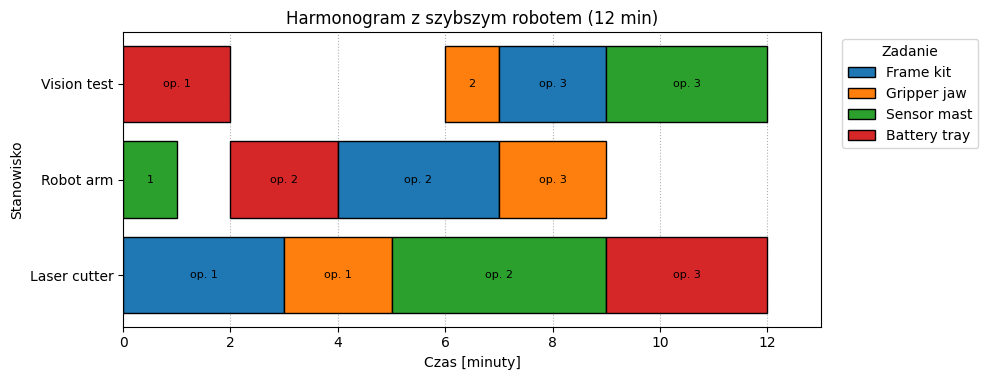

In [ ]:
plot_gantt(new_schedule, title="Harmonogram z szybszym robotem (12 min)");

Rys. 2Harmonogram po skróceniu operacji robota. Laser cutter pracuje bez przerwy od 0 do 12 minuty, więc teraz to on ogranicza komórkę.

### Zadanie 4 — konserwacja Vision test
- Przy oknie 4–6 min harmonogram dalej trwa 13 min, ponieważ Vision test ma 5 min przestoju i solver ustawia przerwę w wolnym czasie.
- Sprawdziliśmy wszystkie 2-minutowe okna. Do okna 6–8 min wynik się nie zmienia. Okno 7–9 daje 14 min, a 8–10 nawet 15 min, bo wtedy Vision test jest potrzebny do kończenia zadań (Rys. 3).
- Przy Laser cutter lub Robot arm każde 2-minutowe okno wydłuża harmonogram do co najmniej 14 min, bo te stanowiska mają tylko 1 min wolnego.
-Wniosek: konserwację planujemy na początku zmiany i na stanowisku z luzem, a nigdy na Laser cutter czy Robot arm w trakcie pracy.

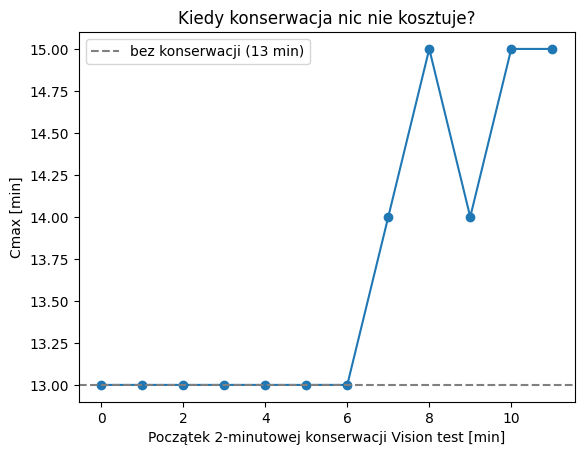

In [ ]:
poczatki = range(0, 12)
czasy = []
for t in poczatki:
    wynik, _, _ = solve_jobshop(jobs, maintenance={"Vision test": (t, t + 2)})
    czasy.append(wynik)

plt.plot(poczatki, czasy, "o-")
plt.axhline(makespan, color="gray", linestyle="--", label="bez konserwacji (13 min)")
plt.xlabel("Początek 2-minutowej konserwacji Vision test [min]")
plt.ylabel("Cmax [min]")
plt.title("Kiedy konserwacja nic nie kosztuje?")
plt.legend()
plt.show()

Rys. 3 Czas zakończenia w zależności od początku konserwacji Vision test. Okna zaczynające się w minutach 0–6 nie wydłużają harmonogramu, a późniejsze dodają 1–2 minuty.

### Wyzwanie — termin Frame kit (10 min)
- Kara za spóźnienie nic nie zmieniła: $Cmax$ = 13 min, a spóźnienie = 0. Frame kit i tak kończy się w 9. minucie.
- Termin 10 min nie był więc ograniczeniem. Krócej niż 9 min też się nie da, bo sama trasa Frame kit trwa 3 + 4 + 2 = 9 min. Termin wcześniejszy niż 9 min oznaczałby spóźnienie niezależnie od harmonogramu.
- Waga 0,5 decyduje o tym, ile minut $Cmax$ jesteśmy gotowi poświęcić za minutę spóźnienia. Tutaj nie miała znaczenia, bo konfliktu nie było.

## Podsumowanie
Solver ułożył harmonogram czterech zestawów w 13 minut, choć suma operacji wynosi 32 minuty. Laser cutter i Robot arm są najbardziej obciążone (po 12 min), więc wyznaczają dolną granicę 12 minut. Skrócenie operacji o minutę pozwala osiągnąć tę granicę, ale tylko wtedy, gdy skracamy operację leżącą na ścieżce opóźniającej koniec. Konserwację warto planować na stanowisku z luzem i we wczesnym oknie, bo wtedy nic nie kosztuje. Model zakłada stałe czasy operacji i brak czasu na przezbrojenia i transport między stanowiskami, więc rzeczywisty harmonogram może być nieco dłuższy.